# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 (scratch) from random initial weights (no ImageNet pretraining), with the untuned `SCRATCH_HYPERPARAMS`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: chronological
Train-time augmentation: on
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']


## Data loaders and class weights

In [2]:
cfg = SCRATCH_HYPERPARAMS

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18 (scratch): micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18 (scratch): micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, target = 32)
Train: 1348 | Val: 323 | Test: 856


## Model

In [3]:
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ResNet-18 (scratch)] Gradient accumulation: 2 micro-batches per optimizer step.


[ResNet-18 (scratch)] Epoch   1/100 | LR: 1.00e-04 | train loss 1.1070 acc 0.457 | val loss 0.9238 acc 0.570 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 1.00e-04 | train loss 0.9572 acc 0.532 | val loss 0.8578 acc 0.576 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 1.00e-04 | train loss 0.8890 acc 0.536 | val loss 0.8344 acc 0.523 *


[ResNet-18 (scratch)] Epoch   4/100 | LR: 1.00e-04 | train loss 0.9116 acc 0.507 | val loss 0.8812 acc 0.582


...

[ResNet-18 (scratch)] Epoch  39/100 | LR: 1.00e-06 | train loss 0.4131 acc 0.812 | val loss 0.5013 acc 0.789


[ResNet-18 (scratch)] Epoch  40/100 | LR: 1.00e-06 | train loss 0.3822 acc 0.794 | val loss 0.5109 acc 0.793


[ResNet-18 (scratch)] Epoch  41/100 | LR: 1.00e-06 | train loss 0.4064 acc 0.805 | val loss 0.5135 acc 0.796


[ResNet-18 (scratch)] Epoch  42/100 | LR: 1.00e-06 | train loss 0.3919 acc 0.800 | val loss 0.5259 acc 0.780


[ResNet-18 (scratch)] Epoch  43/100 | LR: 1.00e-06 | train loss 0.3871 acc 0.810 | val loss 0.4967 acc 0.802

[ResNet-18 (scratch)] No val loss improvement for 10 epochs, stopping at epoch 43.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.4871)


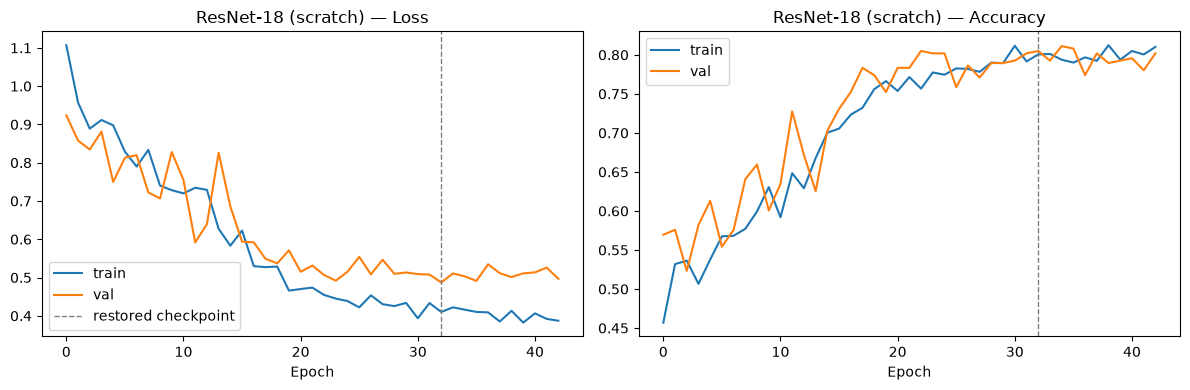

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.713


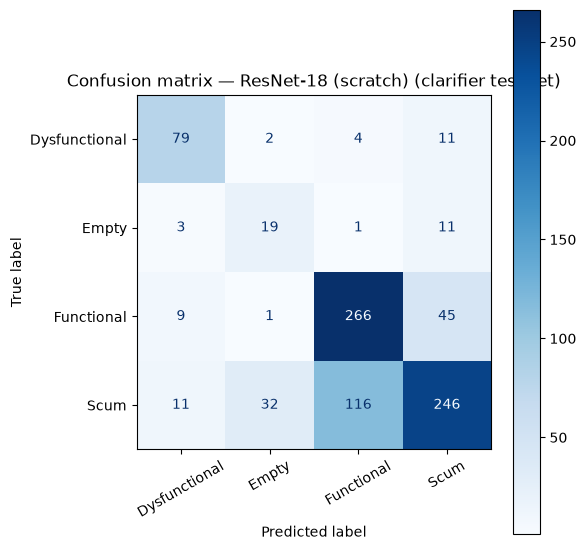

               precision    recall  f1-score   support

Dysfunctional      0.775     0.823     0.798        96
        Empty      0.352     0.559     0.432        34
   Functional      0.687     0.829     0.751       321
         Scum      0.786     0.607     0.685       405

     accuracy                          0.713       856
    macro avg      0.650     0.704     0.667       856
 weighted avg      0.730     0.713     0.713       856



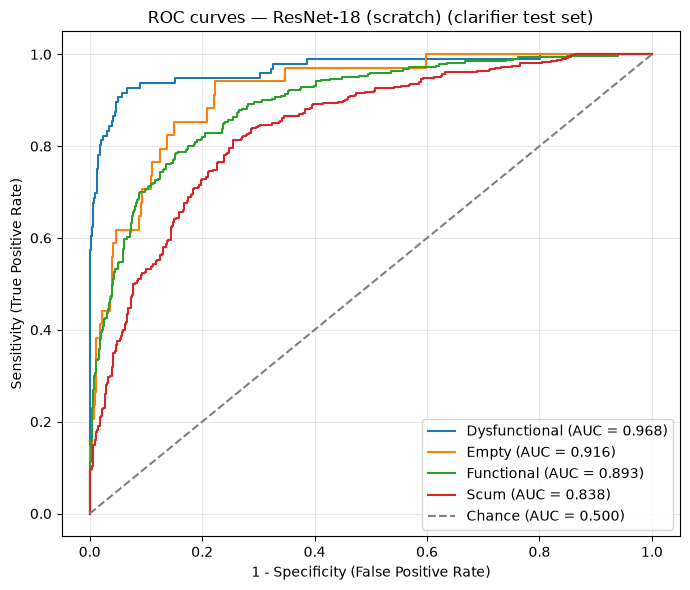

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.968
  Empty          : 0.916
  Functional     : 0.893
  Scum           : 0.838

Mean AUC (over 4/4 classes with test examples): 0.904


(np.float64(0.7126168224299065),
 {'Dysfunctional': 0.9676535087719298,
  'Empty': 0.9161299556318878,
  'Functional': 0.892642734445512,
  'Scum': 0.8381538966904821})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/clarifier_aug/results_clarifier_resnet18_scratch_chronological.pkl
Saved model weights to ../models/pad/clarifier_aug/clarifier_resnet18_scratch_chronological.pt
